# Student Performance Analysis

## Objective
Explore how students' study habits and academic history are associated with their final math grade.

## Questions
1. How are final grades (`G3`) distributed?
2. Is study time associated with final grades?
3. Do students with more past class failures tend to have lower final grades?
4. Are absences associated with final grades?

This analysis describes associations in the dataset; it does not establish causation.

In [18]:
import pandas as pd

df = pd.read_csv("../data/raw/student-mat.csv", sep=";")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [19]:
# Check column names, data types, and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [20]:
# Summary statistics for numeric columns
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [21]:
# Check the values and ranges of the main columns
df[["studytime", "failures", "absences", "G1", "G2", "G3"]].describe()

,studytime,failures,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,2.035443,0.334177,5.708861,10.908861,10.713924,10.415190
std,0.839240,0.743651,8.003096,3.319195,3.761505,4.581443
min,1.000000,0.000000,0.000000,3.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000,8.000000,9.000000,8.000000
50%,2.000000,0.000000,4.000000,11.000000,11.000000,11.000000
75%,2.000000,0.000000,8.000000,13.000000,13.000000,14.000000
max,4.000000,3.000000,75.000000,19.000000,19.000000,20.000000


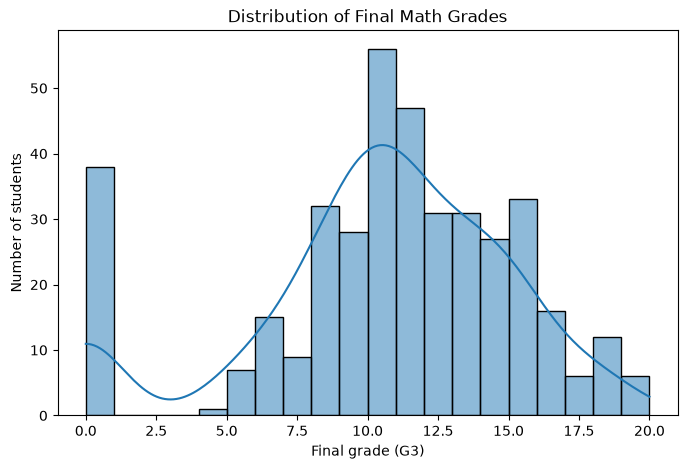

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="G3", bins=20, kde=True)
plt.title("Distribution of Final Math Grades")
plt.xlabel("Final grade (G3)")
plt.ylabel("Number of students")
plt.show()

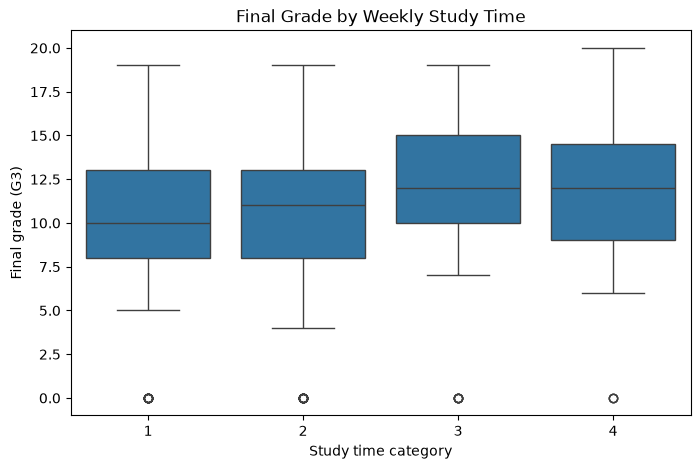

In [23]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="studytime", y="G3")
plt.title("Final Grade by Weekly Study Time")
plt.xlabel("Study time category")
plt.ylabel("Final grade (G3)")
plt.show()

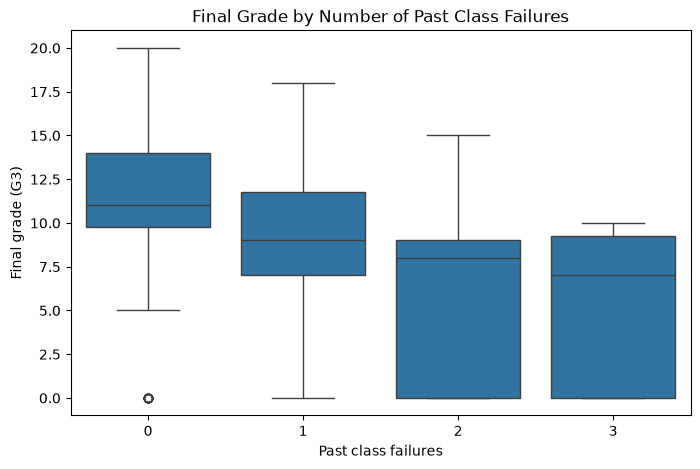

In [24]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="failures", y="G3")
plt.title("Final Grade by Number of Past Class Failures")
plt.xlabel("Past class failures")
plt.ylabel("Final grade (G3)")
plt.show()

In [25]:
df["failures"].value_counts().sort_index()

failures
0    312
1     50
2     17
3     16
Name: count, dtype: int64

Students with more past class failures tend to have lower median final grades in this sample. However, the groups with 2 and 3 failures are much smaller, so their results should be interpreted cautiously. This is an association, not proof of causation.

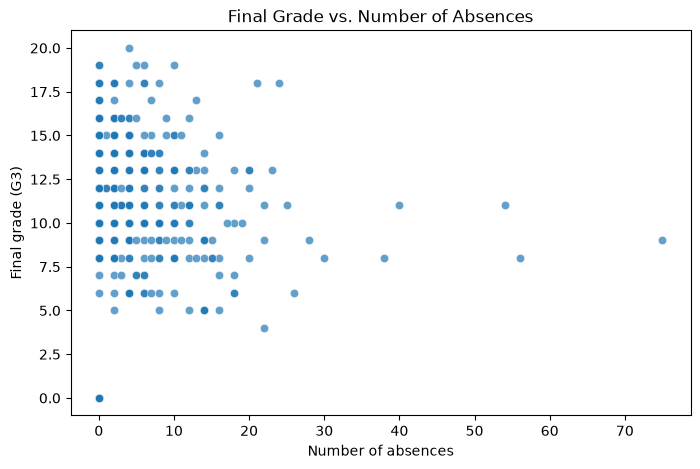

In [26]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="absences", y="G3", alpha=0.7)
plt.title("Final Grade vs. Number of Absences")
plt.xlabel("Number of absences")
plt.ylabel("Final grade (G3)")
plt.show()

### Absences and Final Grades

Most students in this dataset had 0–10 absences, and their final grades varied widely. Students with very high absence counts often had mid-to-low grades, but the pattern is not consistent for every student. This suggests a possible association, not proof that absences cause lower grades.

The few students with unusually high absence counts should be checked, but they should not be removed without a data-quality reason.

In [27]:
studytime_summary = (
    df.groupby("studytime")["G3"]
      .agg(["count", "mean", "median"])
      .round(2)
)

studytime_summary

,count,mean,median
studytime,,,
1,105,10.05,10.0
2,198,10.17,11.0
3,65,11.40,12.0
4,27,11.26,12.0


Students reporting more study time in categories 3 and 4 had higher median final grades than students in categories 1 and 2. The relationship is not perfectly linear, and this observational analysis does not establish causation.

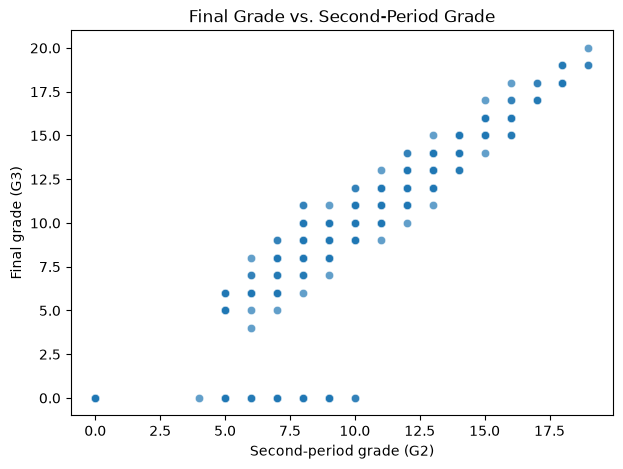

In [28]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="G2", y="G3", alpha=0.7)
plt.title("Final Grade vs. Second-Period Grade")
plt.xlabel("Second-period grade (G2)")
plt.ylabel("Final grade (G3)")
plt.show()

### Observation: Second-Period Grade and Final Grade

The scatter plot shows a strong positive association between G2 and G3: students with higher second-period grades generally have higher final grades. Each point represents a student, and repeated grades create visible stacks of points. Some students have a final grade of zero despite having a nonzero G2 grade; these cases may need further investigation. This plot shows association, not causation.

## Final Grade by School

Compare the average final grade (G3) between students from each school. This helps us see whether the typical final grade differs across the two schools in this dataset.

In [29]:
school_summary = (
    df.groupby("school")["G3"]
    .agg(["count", "mean", "median"])
    .round(2)
)

school_summary

,count,mean,median
school,,,
GP,349,10.49,11.0
MS,46,9.85,10.0


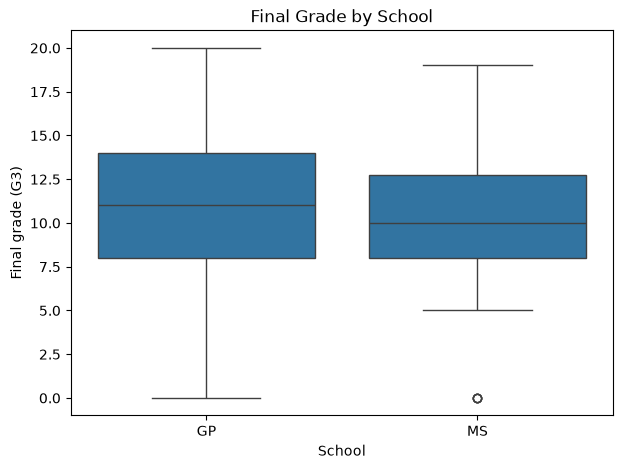

In [30]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="school", y="G3")
plt.title("Final Grade by School")
plt.xlabel("School")
plt.ylabel("Final grade (G3)") 
plt.show()

**Observation:** 
Students from GP had a slightly higher average final grade (10.49) than students from MS (9.85). The medians were 11 and 10, respectively. However, the distributions overlap, and the school groups are unequal in size (349 vs. 46). This comparison shows an association in this dataset, not that attending a particular school causes higher grades.

## Final Grade by Past Class Failures

Explore how students’ final grades vary according to the number of past class failures. Keep in mind that some failure categories have relatively few students.

In [31]:
failure_summary = (
    df.groupby("failures")["G3"]
    .agg(["count", "mean", "median"])
    .round(2)
)

failure_summary

,count,mean,median
failures,,,
0,312,11.25,11.0
1,50,8.12,9.0
2,17,6.24,8.0
3,16,5.69,7.0


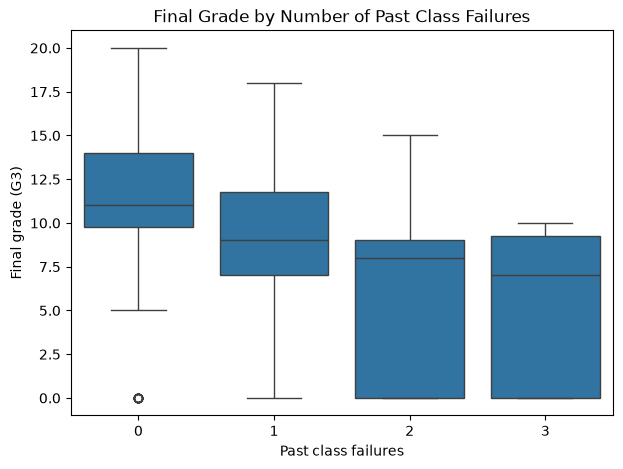

In [32]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="failures", y="G3")
plt.title("Final Grade by Number of Past Class Failures")
plt.xlabel("Past class failures")
plt.ylabel("Final grade (G3)") 
plt.show()

**Observation:** 
Average and median final grades generally decrease as the number of past class failures increases. Students with no past failures had the highest average final grade (11.25), while students with three failures had the lowest (5.69). The groups with two or three failures are small, so these comparisons should be interpreted cautiously. This pattern shows an association, not causation.

## Data Quality Checks

Check for missing values and duplicate rows before finalizing the analysis.

In [33]:
# Count missing values in each column
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [34]:
# Count duplicate rows
df.duplicated().sum()

np.int64(0)

## Key Findings

- Final grades (G3) generally increase with second-period grades (G2), showing a strong positive association.
- Students with more past class failures generally have lower final grades. The groups with two or three failures are small, so those comparisons should be treated cautiously.
- GP students had a slightly higher average final grade than MS students (10.49 vs. 9.85), but the grade distributions overlap and the school groups are unequal in size.
- Median final grades varied only modestly across study-time categories.

## Limitations

- This analysis is observational and shows associations, not cause-and-effect relationships.
- Some groups, especially students with multiple past failures, contain relatively few students.
- The dataset represents students from two schools, so the findings may not generalize to other schools or populations.
- Final grades may be influenced by factors not explored in this analysis.